# E-Commerce Customer Behavior: High Cart Abandonment Prediction

**Dataset:** [E-Commerce Customer Behavior Dataset](https://www.kaggle.com/datasets/srisyra02/ecommerce-customer-behavior-dataset)

---

## Objective

This notebook explores customer engagement signals from an e-commerce platform and builds a **binary classifier** to identify customers with a **high cart abandonment rate**.

Although the raw file is named *churn*, there is **no explicit churn label**. The most actionable supervised target available is `Cart_Abandonment_Rate`, which we convert into:

$$\text{HighAbandon} = \mathbb{1}\{\text{Cart\_Abandonment\_Rate} \geq 70\}$$

The 70% threshold sits near the dataset's upper quartile and aligns with a common industry reference for elevated abandonment risk.

## Scope & assumptions

| Topic | Choice |
|---|---|
| Task | Binary classification (`HighAbandon`) |
| Invalid targets | Drop rows with abandonment rate outside \[0, 100\] |
| Age quality | Treat ages outside \[16, 100\] as missing, then impute |
| Geography | Keep `Country`; drop `City` (high cardinality, strongly collinear with country) |
| Session features | Included in the main model; also evaluated in a sensitivity run without them |
| Temporal framing | Features and target are **same-period aggregates** — associative scoring, not true future churn prediction |

## Notebook roadmap

1. Setup & data loading  
2. Exploratory data analysis  
3. Data cleaning & feature preparation  
4. Modeling & evaluation  
5. Feature importance & sensitivity check  
6. Conclusions  

## 1. Setup & data loading

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 4.5)
RANDOM_STATE = 42
ABANDON_THRESHOLD = 70.0

In [2]:
def get_data_path() -> Path:
    """Resolve data path for Kaggle notebooks or local runs."""
    candidates = [
        Path("/kaggle/input/ecommerce-customer-behavior-dataset"),
        Path("/kaggle/input/datasets/srisyra02/ecommerce-customer-behavior-dataset"),
        Path("."),
    ]
    for path in candidates:
        if (path / "ecommerce_customer_churn_dataset.csv").exists():
            return path
    raise FileNotFoundError("Could not locate ecommerce_customer_churn_dataset.csv")


DATA_PATH = get_data_path()
raw = pd.read_csv(DATA_PATH / "ecommerce_customer_churn_dataset.csv")
print(f"Data path: {DATA_PATH.resolve()}")
print(f"Shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
raw.head()

Data path: /kaggle/input/datasets/srisyra02/ecommerce-customer-behavior-dataset
Shape: 50,000 rows × 10 columns


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items
0,43.0,Male,France,Marseille,2.9,14,27.4,6.0,50.6,3.0
1,36.0,Male,UK,Manchester,1.6,15,42.7,10.3,37.7,1.0
2,45.0,Female,Canada,Vancouver,2.9,10,24.8,1.6,70.9,1.0
3,56.0,Female,USA,New York,2.6,10,38.4,14.8,41.7,9.0
4,35.0,Male,India,Delhi,3.1,29,51.4,NaN,19.1,9.0


### Feature dictionary

| Column | Type | Description |
|---|---|---|
| `Age` | numeric | Customer age |
| `Gender` | categorical | Male / Female |
| `Country` | categorical | Country of residence |
| `City` | categorical | City of residence |
| `Membership_Years` | numeric | Tenure on the platform |
| `Login_Frequency` | numeric | Login activity level |
| `Session_Duration_Avg` | numeric | Average session length |
| `Pages_Per_Session` | numeric | Average pages viewed per session |
| `Cart_Abandonment_Rate` | numeric | Share of carts left without purchase (target source) |
| `Wishlist_Items` | numeric | Items saved to wishlist |

## 2. Exploratory data analysis

We start with schema checks, missingness, distribution shapes, and geographic imbalance — the main data-quality themes for this dataset.

In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    47505 non-null  float64
 1   Gender                 50000 non-null  object 
 2   Country                50000 non-null  object 
 3   City                   50000 non-null  object 
 4   Membership_Years       50000 non-null  float64
 5   Login_Frequency        50000 non-null  int64  
 6   Session_Duration_Avg   46601 non-null  float64
 7   Pages_Per_Session      47000 non-null  float64
 8   Cart_Abandonment_Rate  50000 non-null  float64
 9   Wishlist_Items         46000 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 3.8+ MB


In [4]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,47505.0,37.80,11.83,5.0,29.0,38.0,46.0,200.00
Membership_Years,50000.0,2.98,2.06,0.1,1.4,2.5,4.0,10.00
Login_Frequency,50000.0,11.62,7.81,0.0,6.0,11.0,17.0,46.00
Session_Duration_Avg,46601.0,27.66,10.87,1.0,19.7,26.8,34.7,75.60
Pages_Per_Session,47000.0,8.74,3.78,1.0,6.0,8.4,11.2,24.10
Cart_Abandonment_Rate,50000.0,57.08,16.28,0.0,46.4,58.1,68.7,143.74
Wishlist_Items,46000.0,4.30,3.19,0.0,2.0,4.0,6.0,28.00


### 2.1 Missing values

Four numeric engagement / demographic fields contain missing values. Categorical fields and `Cart_Abandonment_Rate` are complete.

In [5]:
missing = (
    raw.isna()
    .sum()
    .to_frame("missing_count")
    .assign(missing_pct=lambda d: (100 * d["missing_count"] / len(raw)).round(2))
    .sort_values("missing_count", ascending=False)
)
missing

,missing_count,missing_pct
Wishlist_Items,4000,8.00
Session_Duration_Avg,3399,6.80
Pages_Per_Session,3000,6.00
Age,2495,4.99
Gender,0,0.00
Country,0,0.00
Login_Frequency,0,0.00
Membership_Years,0,0.00
City,0,0.00
Cart_Abandonment_Rate,0,0.00


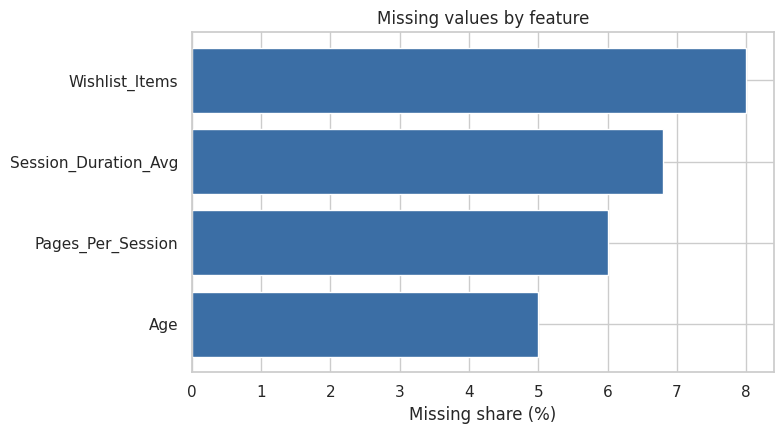

In [6]:
fig, ax = plt.subplots()
plot_df = missing[missing["missing_count"] > 0].sort_values("missing_pct")
ax.barh(plot_df.index, plot_df["missing_pct"], color="#3b6ea5")
ax.set_xlabel("Missing share (%)")
ax.set_title("Missing values by feature")
plt.tight_layout()
plt.show()

### 2.2 Target distribution & invalid rates

A cart abandonment **rate** should lie in \[0, 100\]. Values above 100 are treated as label errors and removed before modeling.

Invalid Cart_Abandonment_Rate rows: 30 (0.060%)
count     30.000000
mean     119.661473
std       13.913497
min      100.658972
25%      104.843620
50%      120.617667
75%      129.662012
max      143.743350
Name: Cart_Abandonment_Rate, dtype: float64


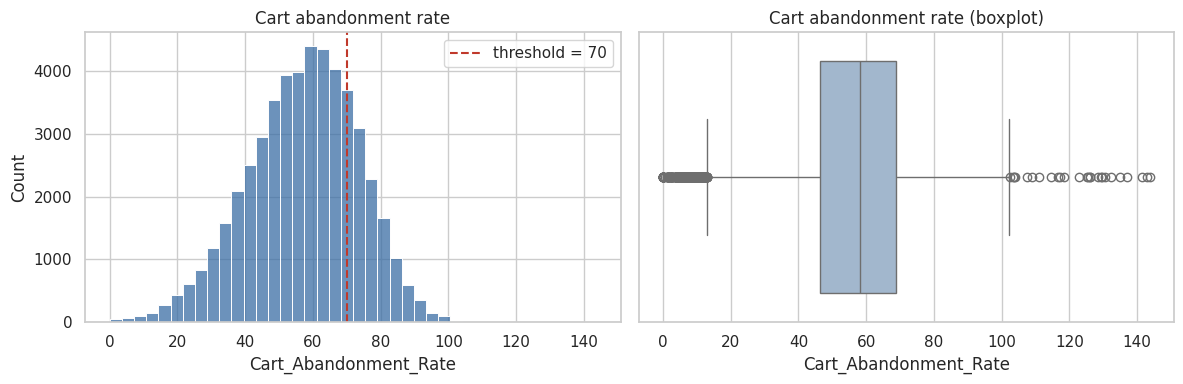

In [7]:
invalid_mask = (raw["Cart_Abandonment_Rate"] < 0) | (raw["Cart_Abandonment_Rate"] > 100)
print(f"Invalid Cart_Abandonment_Rate rows: {invalid_mask.sum():,} "
      f"({100 * invalid_mask.mean():.3f}%)")
print(raw.loc[invalid_mask, "Cart_Abandonment_Rate"].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(raw["Cart_Abandonment_Rate"], bins=40, ax=axes[0], color="#3b6ea5")
axes[0].axvline(ABANDON_THRESHOLD, color="#c0392b", linestyle="--", label=f"threshold = {ABANDON_THRESHOLD:.0f}")
axes[0].set_title("Cart abandonment rate")
axes[0].legend()

sns.boxplot(x=raw["Cart_Abandonment_Rate"], ax=axes[1], color="#9bb7d4")
axes[1].set_title("Cart abandonment rate (boxplot)")
plt.tight_layout()
plt.show()

### 2.3 Age anomalies

`Age` ranges from 5 to 200 in the raw file. Extreme values (especially 150 / 200) are almost certainly data errors.

Ages outside [16, 100]: 50


Age
5.0      16
10.0     14
150.0     9
200.0    11
Name: count, dtype: int64

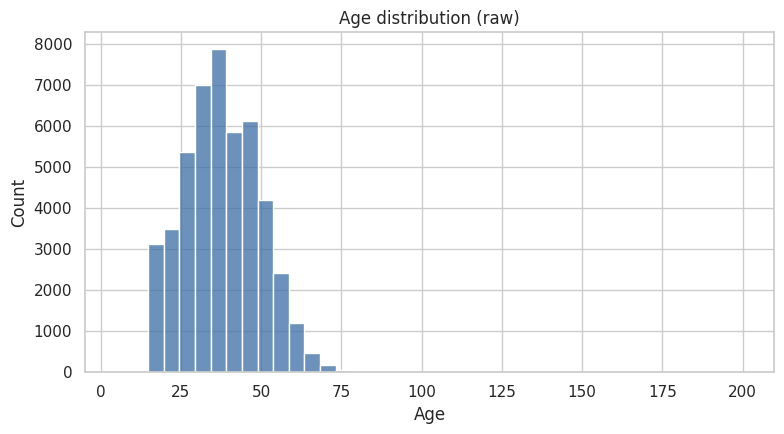

In [8]:
age_odd = raw[(raw["Age"] < 16) | (raw["Age"] > 100)]
print(f"Ages outside [16, 100]: {len(age_odd):,}")
display(age_odd["Age"].value_counts().sort_index())

fig, ax = plt.subplots()
sns.histplot(raw["Age"].dropna(), bins=40, ax=ax, color="#3b6ea5")
ax.set_title("Age distribution (raw)")
plt.tight_layout()
plt.show()

### 2.4 Geographic imbalance

The customer base is heavily skewed toward the **USA**, and US cities dominate city counts. Global averages will therefore be US-weighted unless we stratify or encode geography carefully.

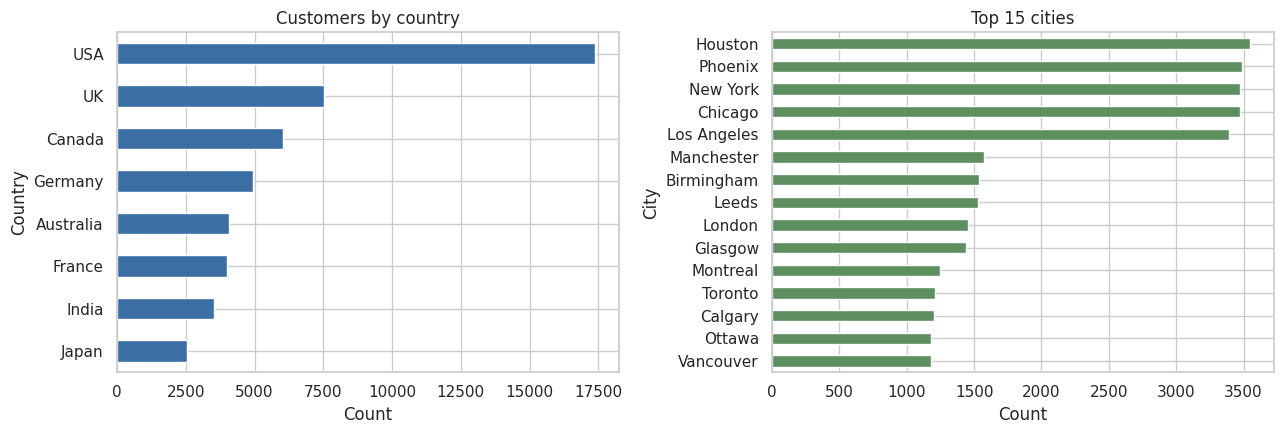

,count,pct
Country,,
USA,17384,34.77
UK,7534,15.07
Canada,6023,12.05
Germany,4925,9.85
Australia,4061,8.12
France,4013,8.03
India,3512,7.02
Japan,2548,5.10


In [9]:
country_counts = raw["Country"].value_counts()
city_counts = raw["City"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
country_counts.sort_values().plot(kind="barh", ax=axes[0], color="#3b6ea5")
axes[0].set_title("Customers by country")
axes[0].set_xlabel("Count")

city_counts.head(15).sort_values().plot(kind="barh", ax=axes[1], color="#5d8f61")
axes[1].set_title("Top 15 cities")
axes[1].set_xlabel("Count")
plt.tight_layout()
plt.show()

display(country_counts.to_frame("count").assign(pct=lambda d: (100 * d["count"] / len(raw)).round(2)))

### 2.5 Behavioral correlations

We inspect how numeric engagement features relate to each other and to cart abandonment.

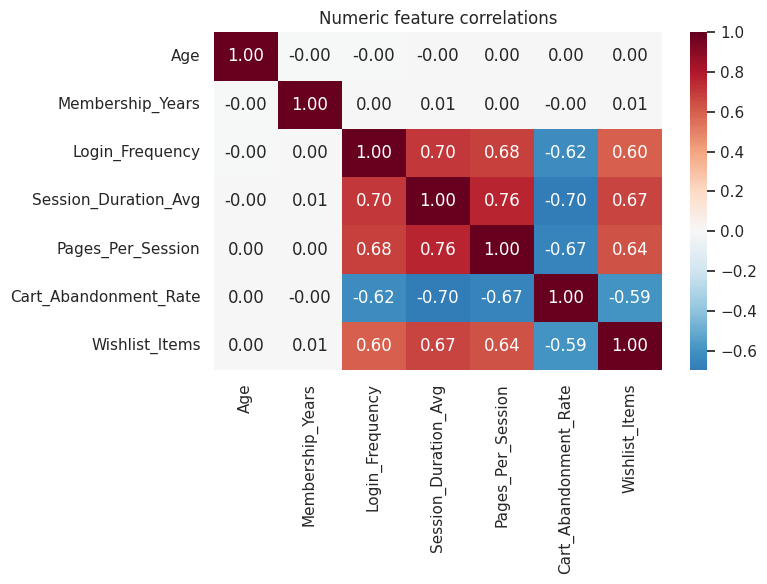

In [10]:
num_cols = [
    "Age",
    "Membership_Years",
    "Login_Frequency",
    "Session_Duration_Avg",
    "Pages_Per_Session",
    "Cart_Abandonment_Rate",
    "Wishlist_Items",
]

corr = raw[num_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Numeric feature correlations")
plt.tight_layout()
plt.show()

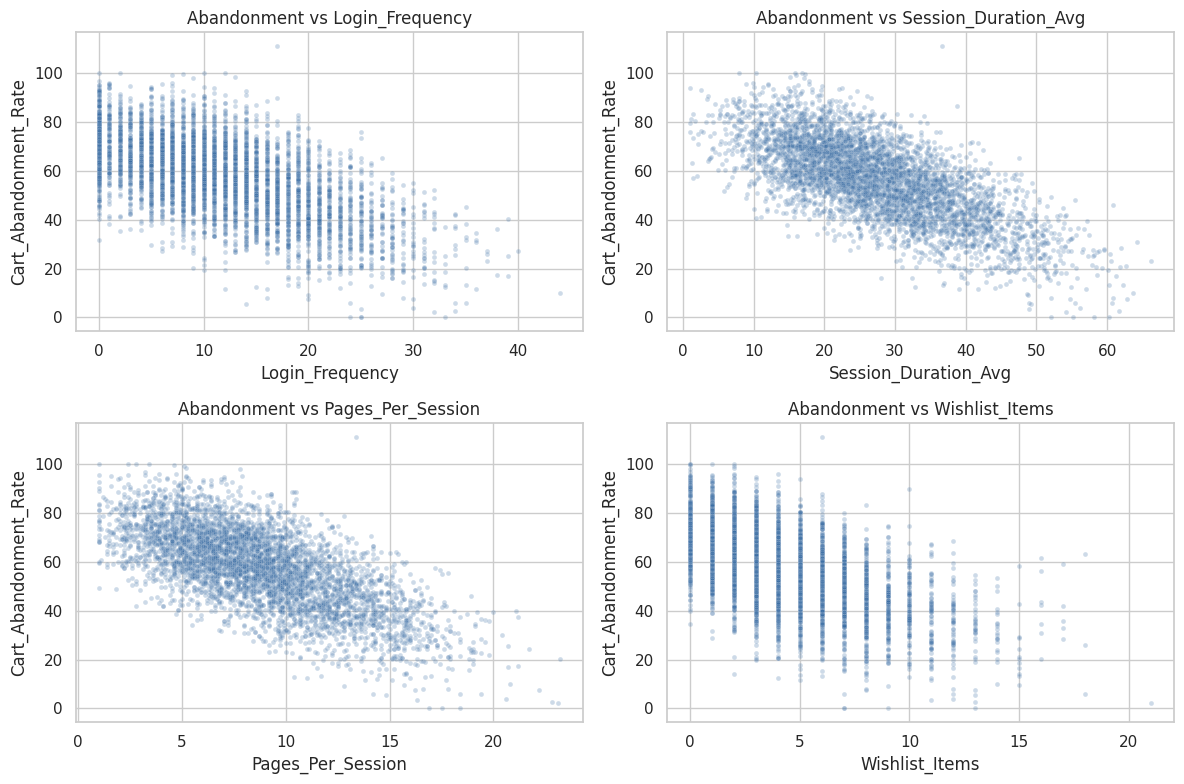

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
pairs = [
    ("Login_Frequency", axes[0, 0]),
    ("Session_Duration_Avg", axes[0, 1]),
    ("Pages_Per_Session", axes[1, 0]),
    ("Wishlist_Items", axes[1, 1]),
]
for col, ax in pairs:
    sns.scatterplot(
        data=raw.sample(n=min(5000, len(raw)), random_state=RANDOM_STATE),
        x=col,
        y="Cart_Abandonment_Rate",
        alpha=0.25,
        s=12,
        ax=ax,
        color="#3b6ea5",
    )
    ax.set_title(f"Abandonment vs {col}")
plt.tight_layout()
plt.show()

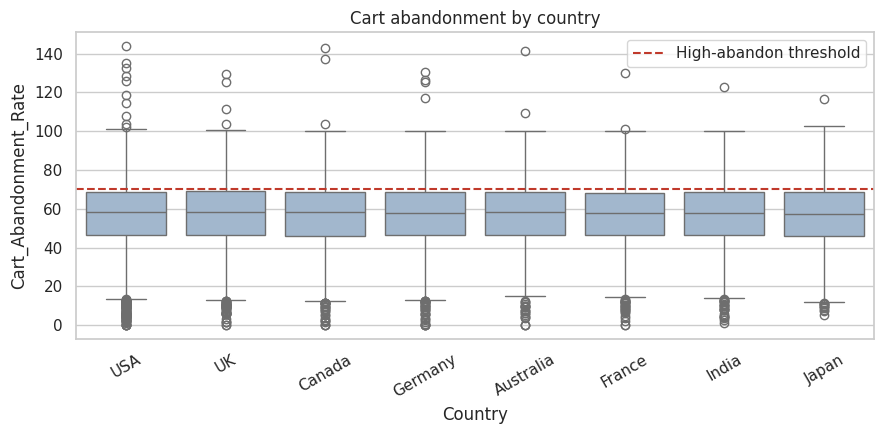

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(
    data=raw,
    x="Country",
    y="Cart_Abandonment_Rate",
    order=raw["Country"].value_counts().index,
    ax=ax,
    color="#9bb7d4",
)
ax.axhline(ABANDON_THRESHOLD, color="#c0392b", linestyle="--", label="High-abandon threshold")
ax.set_title("Cart abandonment by country")
ax.tick_params(axis="x", rotation=30)
ax.legend()
plt.tight_layout()
plt.show()

**EDA takeaways**

- Missingness is concentrated in `Wishlist_Items`, `Session_Duration_Avg`, `Pages_Per_Session`, and `Age` (about 5–8% each).
- `Age` and `Cart_Abandonment_Rate` both contain impossible values that must be cleaned before modeling.
- Geography is imbalanced: USA alone accounts for roughly one third of rows.
- Engagement metrics (logins, session depth) are the most natural predictors of abandonment risk.

## 3. Data cleaning & feature preparation

Cleaning rules applied below:

1. Drop rows with `Cart_Abandonment_Rate` outside \[0, 100\] (invalid **labels**).
2. Convert `Age` outside \[16, 100\] to missing (invalid **features**).
3. Create binary target `HighAbandon` at threshold 70.
4. Drop `City` to limit cardinality / leakage of US-city dominance into the model.
5. Impute remaining numeric nulls inside the sklearn pipeline (median), so train/test leakage is avoided.

In [13]:
def clean_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()

    before = len(out)
    out = out[out["Cart_Abandonment_Rate"].between(0, 100)].copy()
    dropped_labels = before - len(out)

    age_invalid = ~out["Age"].between(16, 100, inclusive="both") & out["Age"].notna()
    n_age_fixed = int(age_invalid.sum())
    out.loc[age_invalid, "Age"] = np.nan

    out["HighAbandon"] = (out["Cart_Abandonment_Rate"] >= ABANDON_THRESHOLD).astype(int)

    print(f"Dropped invalid abandonment labels: {dropped_labels:,}")
    print(f"Age values set to NaN (outside [16, 100]): {n_age_fixed:,}")
    print(f"Rows remaining: {len(out):,}")
    print("HighAbandon class balance:")
    print(out["HighAbandon"].value_counts(normalize=True).rename({0: "low/medium", 1: "high"}).round(4))
    return out


df = clean_dataframe(raw)
df.head()

Dropped invalid abandonment labels: 30
Age values set to NaN (outside [16, 100]): 50
Rows remaining: 49,970
HighAbandon class balance:
HighAbandon
low/medium    0.7771
high          0.2229
Name: proportion, dtype: float64


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,HighAbandon
0,43.0,Male,France,Marseille,2.9,14,27.4,6.0,50.6,3.0,0
1,36.0,Male,UK,Manchester,1.6,15,42.7,10.3,37.7,1.0,0
2,45.0,Female,Canada,Vancouver,2.9,10,24.8,1.6,70.9,1.0,1
3,56.0,Female,USA,New York,2.6,10,38.4,14.8,41.7,9.0,0
4,35.0,Male,India,Delhi,3.1,29,51.4,NaN,19.1,9.0,0


In [14]:
TARGET = "HighAbandon"
DROP_COLS = ["Cart_Abandonment_Rate", "City", TARGET]

feature_cols = [c for c in df.columns if c not in DROP_COLS]
X = df[feature_cols].copy()
y = df[TARGET].copy()

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Train size: {len(X_train):,} | Test size: {len(X_test):,}")
print(f"Positive rate — train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

Numeric features: ['Age', 'Membership_Years', 'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Wishlist_Items']
Categorical features: ['Gender', 'Country']
Train size: 39,976 | Test size: 9,994
Positive rate — train: 0.223 | test: 0.223


In [15]:
numeric_pipe = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_pipe = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features),
    ]
)

## 4. Modeling & evaluation

We compare three classifiers on the same preprocessed features:

- **Logistic Regression** — strong linear baseline, easy to interpret  
- **Random Forest** — non-linear interactions, robust defaults  
- **HistGradientBoosting** — strong tabular booster built into scikit-learn  

Primary metrics: **ROC-AUC**, **F1** (positive class), plus precision / recall.

In [16]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_depth=6,
        learning_rate=0.08,
        max_iter=300,
        random_state=RANDOM_STATE,
    ),
}


def evaluate_model(name: str, estimator, X_tr, y_tr, X_te, y_te) -> dict:
    pipe = Pipeline([("preprocess", preprocess), ("model", estimator)])
    pipe.fit(X_tr, y_tr)

    proba = pipe.predict_proba(X_te)[:, 1]
    pred = (proba >= 0.5).astype(int)

    metrics = {
        "model": name,
        "roc_auc": roc_auc_score(y_te, proba),
        "f1": f1_score(y_te, pred),
        "pipeline": pipe,
        "y_true": y_te,
        "y_pred": pred,
        "y_proba": proba,
    }
    return metrics


results = [evaluate_model(n, m, X_train, y_train, X_test, y_test) for n, m in models.items()]
leaderboard = (
    pd.DataFrame(results)[["model", "roc_auc", "f1"]]
    .sort_values(["roc_auc", "f1"], ascending=False)
    .reset_index(drop=True)
)
leaderboard.round(4)

,model,roc_auc,f1
0,HistGradientBoosting,0.8419,0.4850
1,Random Forest,0.8387,0.5745
2,Logistic Regression,0.8352,0.5717


Best model by ROC-AUC: HistGradientBoosting

              precision    recall  f1-score   support

           0      0.844     0.922     0.881      7767
           1      0.599     0.407     0.485      2227

    accuracy                          0.807      9994
   macro avg      0.722     0.665     0.683      9994
weighted avg      0.790     0.807     0.793      9994



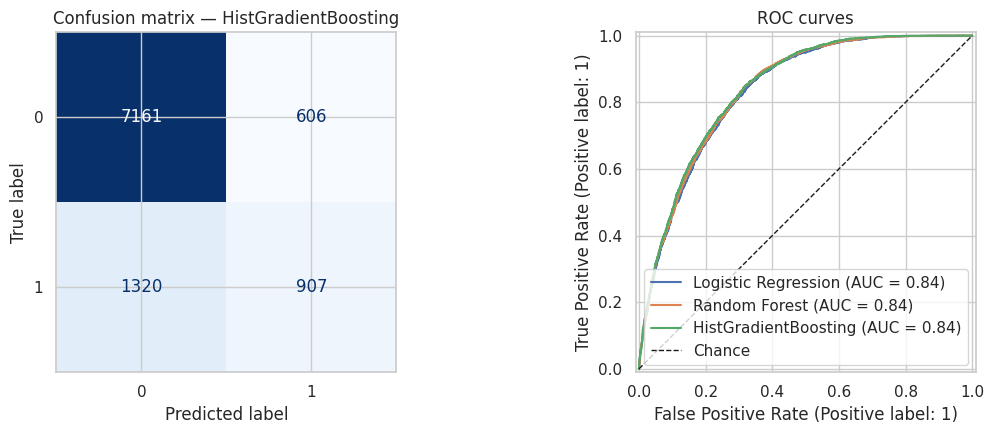

In [17]:
best = max(results, key=lambda r: r["roc_auc"])
print(f"Best model by ROC-AUC: {best['model']}\n")
print(classification_report(best["y_true"], best["y_pred"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(
    best["y_true"], best["y_pred"], ax=axes[0], colorbar=False, cmap="Blues"
)
axes[0].set_title(f"Confusion matrix — {best['model']}")

for res in results:
    RocCurveDisplay.from_predictions(res["y_true"], res["y_proba"], name=res["model"], ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1, label="Chance")
axes[1].set_title("ROC curves")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5. Feature importance & sensitivity check

### 5.1 What drives the best model?

For tree-based models we read impurity-based importances on the transformed feature names. For logistic regression we fall back to absolute coefficients.

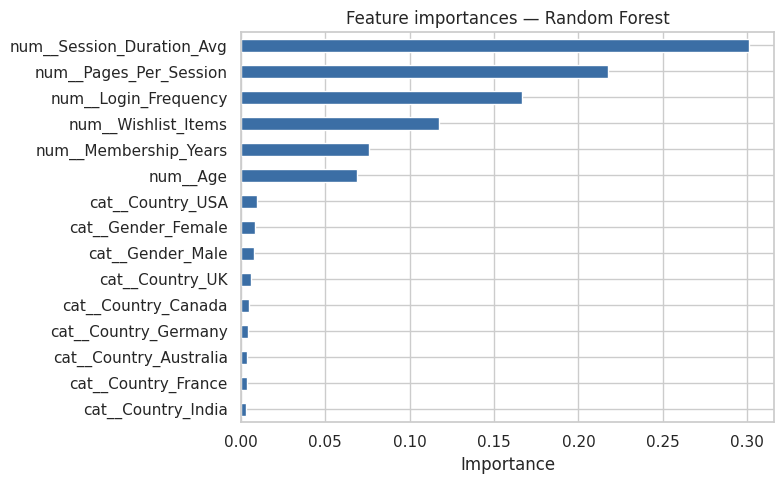

In [18]:
def get_feature_names(fitted_preprocess: ColumnTransformer) -> list[str]:
    return fitted_preprocess.get_feature_names_out().tolist()


def plot_importances(result: dict, top_n: int = 15) -> None:
    pipe = result["pipeline"]
    model = pipe.named_steps["model"]
    names = get_feature_names(pipe.named_steps["preprocess"])

    if hasattr(model, "feature_importances_"):
        values = model.feature_importances_
        title = f"Feature importances — {result['model']}"
    elif hasattr(model, "coef_"):
        values = np.abs(model.coef_).ravel()
        title = f"|Coefficients| — {result['model']}"
    else:
        print(f"No native importance available for {result['model']}")
        return

    imp = (
        pd.Series(values, index=names)
        .sort_values(ascending=False)
        .head(top_n)
        .sort_values()
    )
    fig, ax = plt.subplots(figsize=(8, 5))
    imp.plot(kind="barh", ax=ax, color="#3b6ea5")
    ax.set_title(title)
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.show()


# Prefer a tree model for importances when available
importance_result = next(
    (r for r in results if r["model"] == "Random Forest"),
    best,
)
plot_importances(importance_result)

### 5.2 Sensitivity: without session-depth features

`Session_Duration_Avg` and `Pages_Per_Session` are **not classic leakage** (they are not computed from the target), but they are **same-period behavioral aggregates**.  
A production early-warning system might not observe final session depth before abandonment unfolds.

We therefore retrain the best model family **without** those two features and compare ROC-AUC / F1.

In [19]:
session_cols = ["Session_Duration_Avg", "Pages_Per_Session"]
X_train_red = X_train.drop(columns=session_cols)
X_test_red = X_test.drop(columns=session_cols)

numeric_features_red = X_train_red.select_dtypes(include=["number"]).columns.tolist()
categorical_features_red = X_train_red.select_dtypes(exclude=["number"]).columns.tolist()

preprocess_red = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            numeric_features_red,
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            categorical_features_red,
        ),
    ]
)

reduced_estimator = models[best["model"]]
# Recreate a fresh estimator with the same hyperparameters
reduced_estimator = models[best["model"]].__class__(**models[best["model"]].get_params())

pipe_red = Pipeline([("preprocess", preprocess_red), ("model", reduced_estimator)])
pipe_red.fit(X_train_red, y_train)
proba_red = pipe_red.predict_proba(X_test_red)[:, 1]
pred_red = (proba_red >= 0.5).astype(int)

sensitivity = pd.DataFrame(
    [
        {
            "feature_set": "All features",
            "roc_auc": best["roc_auc"],
            "f1": best["f1"],
        },
        {
            "feature_set": "Without session duration & pages",
            "roc_auc": roc_auc_score(y_test, proba_red),
            "f1": f1_score(y_test, pred_red),
        },
    ]
)
sensitivity.round(4)

,feature_set,roc_auc,f1
0,All features,0.8419,0.4850
1,Without session duration & pages,0.8059,0.3994


## 6. Conclusions

### What we built

- A full **EDA → cleaning → classification** workflow on 50k e-commerce customer profiles.
- A business-oriented label: **high cart abandonment** at a **70%** threshold.
- A fair comparison of linear and tree-based models with proper train-only imputation.

### Practical implications

- Customers with weaker engagement (fewer logins / shallower sessions) are the natural risk pool for retention campaigns.
- Because the USA dominates the sample, country-level monitoring matters: a global score can mask regional differences.
- The reduced-feature sensitivity run clarifies how much performance depends on session-depth signals versus earlier demographic / tenure / login cues.

### Limitations

- There is **no true churn timestamp or outcome**; this is an abandonment-risk score on contemporaneous aggregates.
- Invalid ages and abandonment rates suggest synthetic / noisy fields — cleaned, but still imperfect.
- City was dropped for cardinality and imbalance reasons; a hierarchical country→city encoding could be revisited.

### Next steps

1. Tune the abandonment threshold (65 / 70 / 75) against campaign capacity.  
2. Add cost-sensitive thresholds on predicted probability (optimize recall for outreach).  
3. If longitudinal logs become available, rebuild the label as **future** abandonment and use lagged features only.  
4. Optional unsupervised companion: cluster customers into engagement personas for CRM playbooks.

---

*Dataset source: [srisyra02/ecommerce-customer-behavior-dataset](https://www.kaggle.com/datasets/srisyra02/ecommerce-customer-behavior-dataset)*